# Exploratory Data Analysis: Malaysia GeoNames (`MY.txt`)

This notebook explores the GeoNames extract for Malaysia before we use it for the TSP project.
The project brief asks us to document:

- which records and columns we use,
- why we chose that subset,
- the filtering and preprocessing we performed,
- any derived attributes we added.

**Sections**

1. Setup and loading
2. Dataset overview
3. Data dictionary
4. Missing values
5. Duplicates and consistency
6. Categorical columns
7. Numeric columns
8. Geographic distribution
9. Cleaning
10. Choosing the TSP problem size
11. Summary of findings

## 1. Setup and loading

`MY.txt` is tab-delimited UTF-8 with **no header row**, so we name the 19 columns from `data/Metadata.txt`.

Loading choices:

- The admin code columns are read as strings, so codes like `02` keep their leading zero.
- `quoting=3` (`csv.QUOTE_NONE`) stops pandas from treating `"` inside place names as a field quote.
- `keep_default_na=False` with `na_values=[""]` means only truly empty fields become missing.
  Without this, a place literally named `NA` or `None` would be read as missing.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("data")

COLUMNS = [
    "geonameid", "name", "asciiname", "alternatenames",
    "latitude", "longitude", "feature_class", "feature_code",
    "country_code", "cc2", "admin1_code", "admin2_code",
    "admin3_code", "admin4_code", "population", "elevation",
    "dem", "timezone", "modification_date",
]

df = pd.read_csv(
    DATA_DIR / "MY.txt",
    sep="\t",
    header=None,
    names=COLUMNS,
    dtype={
        "admin1_code": "string", "admin2_code": "string",
        "admin3_code": "string", "admin4_code": "string",
        "cc2": "string", "elevation": "Int64",
    },
    parse_dates=["modification_date"],
    keep_default_na=False,
    na_values=[""],
    quoting=3,  # csv.QUOTE_NONE: names may contain quote characters
    encoding="utf-8",
)

# Plot style: recessive axes, one accent hue for single-series charts.
ACCENT, MUTED = "#2a78d6", "#a3a29c"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e8e7e3",
    "axes.axisbelow": True, "axes.titleweight": "bold",
})
pd.set_option("display.max_columns", 30)

df.shape

(71709, 19)

## 2. Dataset overview

There are **71,709 rows** and 19 columns. Each row is one named geographic feature: a village, river, hill, hotel, and so on.
Only some of these rows are places a salesperson would visit.

In [2]:
df.head()

,geonameid,name,asciiname,alternatenames,latitude,longitude,feature_class,feature_code,country_code,cc2,admin1_code,admin2_code,admin3_code,admin4_code,population,elevation,dem,timezone,modification_date
0,1222381,Langkawi,Langkawi,"Langkawi,Langkawi Permata Kedah",6.35608,99.78375,A,ADM2,MY,<NA>,02,0207,<NA>,<NA>,64792,<NA>,28,Asia/Kuala_Lumpur,2021-04-18
1,1222382,Pasir Hitam,Pasir Hitam,NaN,6.42511,99.79453,P,PPL,MY,<NA>,02,0207,<NA>,<NA>,0,<NA>,15,Asia/Kuala_Lumpur,2021-04-17
2,1222383,Tanjung Belua,Tanjung Belua,NaN,6.36147,99.65685,T,PT,MY,<NA>,02,0207,<NA>,<NA>,0,<NA>,51,Asia/Kuala_Lumpur,2021-04-17
3,1222384,Kuala Melaka,Kuala Melaka,NaN,6.35383,99.71622,H,STMM,MY,<NA>,02,<NA>,<NA>,<NA>,0,<NA>,-9999,Asia/Kuala_Lumpur,2008-08-06
4,1222385,Pelabuhan Bass,Pelabuhan Bass,"Bass Harbour,Pelabohan Bass,Pelabuhan Bass",6.31667,99.83333,H,HBR,MY,<NA>,02,<NA>,<NA>,<NA>,0,<NA>,-9999,Asia/Kuala_Lumpur,2012-01-17


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 71709 entries, 0 to 71708
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   geonameid          71709 non-null  int64         
 1   name               71709 non-null  str           
 2   asciiname          71709 non-null  str           
 3   alternatenames     44483 non-null  str           
 4   latitude           71709 non-null  float64       
 5   longitude          71709 non-null  float64       
 6   feature_class      71709 non-null  str           
 7   feature_code       71709 non-null  str           
 8   country_code       71709 non-null  str           
 9   cc2                35 non-null     string        
 10  admin1_code        71676 non-null  string        
 11  admin2_code        36375 non-null  string        
 12  admin3_code        278 non-null    string        
 13  admin4_code        4 non-null      string        
 14  population       

## 3. Data dictionary

The table below explains each column and how relevant it is to a TSP use case.
Definitions are from `data/Metadata.txt` and the [GeoNames feature codes](https://www.geonames.org/export/codes.html).

| Column | Meaning | Use for TSP |
|---|---|---|
| `geonameid` | Unique integer ID of the record | **Keep**: stable node ID |
| `name` | Place name (UTF-8, may contain non-ASCII such as `’`) | **Keep**: label |
| `asciiname` | `name` transliterated to plain ASCII | Optional: safe for console output |
| `alternatenames` | Comma-separated other names / spellings | Drop |
| `latitude`, `longitude` | WGS84 decimal degrees | **Keep**: needed to compute distances |
| `feature_class` | 1-letter category (A, H, L, P, R, S, T, U, V; see section 6) | **Keep**: filter to populated places |
| `feature_code` | Finer category, e.g. `PPL` village, `PPLA` state capital, `PPLC` national capital | **Keep**: city importance / priority |
| `country_code` | ISO country code; always `MY` here | Drop (constant) |
| `cc2` | Alternate country codes for border features | Drop |
| `admin1_code` | State code (FIPS), e.g. `14` = Kuala Lumpur | **Keep**: map to state name; useful for clustering |
| `admin2_code` | District code | Optional |
| `admin3_code`, `admin4_code` | Sub-district codes; almost always empty | Drop |
| `population` | Population; `0` means **unknown**, not zero people | **Keep**: city weight / priority |
| `elevation` | Surveyed elevation in metres; mostly empty | Drop (use `dem`) |
| `dem` | Model elevation (SRTM3/GTOPO30) in metres; `-9999` = no data | Optional |
| `timezone` | IANA time zone | Drop: all MY places are UTC+8 in practice |
| `modification_date` | Last edit date in GeoNames | Drop |

## 4. Missing values

We check two kinds of missing data:

1. **Explicit**: empty fields, shown as `NaN` / `<NA>`.
2. **Hidden**: placeholder values that mean "unknown" but look like real numbers.

In [4]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

,missing,missing_%
admin4_code,71705,99.99
cc2,71674,99.95
admin3_code,71431,99.61
elevation,69261,96.59
admin2_code,35334,49.27
alternatenames,27226,37.97
timezone,156,0.22
admin1_code,33,0.05


**Why each column is empty**

- `admin4_code`, `admin3_code`, `cc2`: GeoNames rarely uses these levels for Malaysia.
  `cc2` is only set for features that cross a border (Thailand, Indonesia, Brunei).
- `elevation` (~97% empty): only surveyed points such as peaks have it. `dem` is the filled-in alternative.
- `admin2_code` (~49% empty): many natural features (rivers, hills) are not assigned to a district.
- `alternatenames` (~38% empty): many small places have only one name.
- `timezone` (156 rows) and `admin1_code` (33 rows): mostly offshore features (reefs, shoals) and a few recently added urban points.

None of the empty columns block a basic TSP: **latitude, longitude, name and feature class are complete.**

In [5]:
hidden = pd.Series({
    "population == 0": (df["population"] == 0).sum(),
    "dem == -9999": (df["dem"] == -9999).sum(),
    "elevation == 0": (df["elevation"] == 0).sum(),
}, name="rows")
pd.DataFrame({"rows": hidden, "%": (hidden / len(df) * 100).round(2)})

,rows,%
population == 0,70918,98.90
dem == -9999,1613,2.25
elevation == 0,126,0.18


**Hidden missing values**

- `population == 0` in **~99% of rows**. GeoNames uses 0 for "not recorded".
  Only 791 rows have a population, so any population-weighted variant must restrict to these.
- `dem == -9999` is the SRTM "no data" sentinel, mostly for points at sea. Treat it as `NaN`.

## 5. Duplicates and consistency

In [6]:
pd.Series({
    "duplicate geonameid": df["geonameid"].duplicated().sum(),
    "fully duplicate rows": df.duplicated().sum(),
    "duplicate (name, lat, lon)": df.duplicated(["name", "latitude", "longitude"]).sum(),
    "duplicate (lat, lon)": df.duplicated(["latitude", "longitude"]).sum(),
    "duplicate name": df["name"].duplicated().sum(),
})

duplicate geonameid               0
fully duplicate rows              0
duplicate (name, lat, lon)       25
duplicate (lat, lon)          11352
duplicate name                15520
dtype: int64

- `geonameid` is unique and there are no fully duplicated rows.
- Many rows share coordinates. This is expected: a river mouth, a village and a hill can be recorded at the same rounded point.
  For TSP this matters, because **two nodes at distance 0** can confuse some heuristics. We re-check after filtering.
- Names repeat a lot (`Kampung Baru`, `Sungai Besar`, ...). **Do not use `name` as a key**; use `geonameid`.

In [7]:
df.loc[df.duplicated(["name", "latitude", "longitude"], keep=False),
       ["geonameid", "name", "feature_code", "latitude", "longitude"]].sort_values("name").head(10)

,geonameid,name,feature_code,latitude,longitude
2306,1734697,Batu Rakit,PPL,5.45000,103.05000
16746,1749254,Batu Rakit,RKS,5.45000,103.05000
53747,7064136,Bukit Tujuh Ratus,HLL,4.39829,118.18135
53764,7064154,Bukit Tujuh Ratus,TRIG,4.39829,118.18135
52704,6823191,Datuk Keramat,PPLX,5.41064,100.31976
52727,6823214,Datuk Keramat,ADM3,5.41064,100.31976
1268,1733648,Gaya,MT,4.61450,118.73390
53737,7064126,Gaya,TRIG,4.61450,118.73390
41459,1774098,Guntong,HLL,1.10000,111.55000
41460,1774099,Guntong,PPL,1.10000,111.55000


Same name and same coordinates, but different feature codes. Usually this is a place and a nearby feature (for example a village and its river).
These are distinct records, not errors.

**Consistency checks**

In [8]:
print("country_code values:", df["country_code"].unique())
print()
print(df["timezone"].value_counts(dropna=False))

country_code values: <ArrowStringArray>
['MY']
Length: 1, dtype: str

timezone
Asia/Kuala_Lumpur    46968
Asia/Kuching         24499
NaN                    156
Asia/Pontianak          38
Asia/Brunei             23
Asia/Bangkok            13
Asia/Makassar            7
Asia/Manila              4
Asia/Singapore           1
Name: count, dtype: int64


- `country_code` is `MY` for every row, so it carries no information.
- Most rows are `Asia/Kuala_Lumpur` (Peninsular) or `Asia/Kuching` (Sabah and Sarawak). Both are UTC+8.
- A few rows use neighbouring zones (`Asia/Pontianak`, `Asia/Brunei`, ...). These are border or offshore features.

## 6. Categorical columns

### Feature class

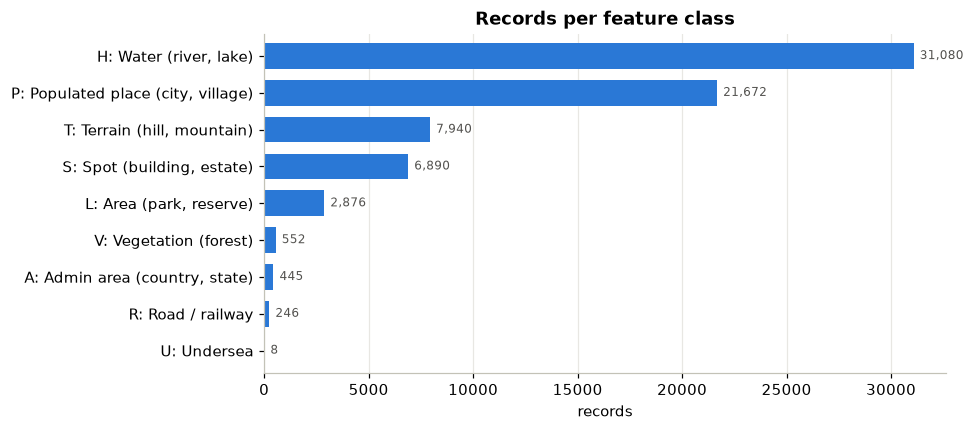

In [9]:
FEATURE_CLASS = {
    "A": "Admin area (country, state)", "H": "Water (river, lake)",
    "L": "Area (park, reserve)", "P": "Populated place (city, village)",
    "R": "Road / railway", "S": "Spot (building, estate)",
    "T": "Terrain (hill, mountain)", "U": "Undersea", "V": "Vegetation (forest)",
}
fc = df["feature_class"].value_counts()
fc.index = [f"{k}: {FEATURE_CLASS[k]}" for k in fc.index]

ax = fc.sort_values().plot.barh(color=ACCENT, figsize=(8, 4), width=0.7)
ax.set_title("Records per feature class")
ax.set_xlabel("records")
ax.grid(axis="y", visible=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_width()):,}", (p.get_width(), p.get_y() + p.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
plt.show()

Water features (`H`, mostly streams) are the largest class.
**Populated places (`P`, 21,672 rows)** are the natural TSP nodes, because a salesperson visits towns, not rivers.
`S` (spots such as hotels and estates) could also be used for a delivery or tourism use case.

### Feature codes inside the populated-place class

In [10]:
df.loc[df["feature_class"] == "P", "feature_code"].value_counts()

feature_code
PPL      21381
PPLX       146
PPLQ        89
PPLL        14
PPLA        13
PPLF         7
PPLA2        6
PPLH         5
PPLS         4
PPLA3        3
PPLW         2
PPLC         1
PPLG         1
Name: count, dtype: int64

| Code | Meaning |
|---|---|
| `PPL` | populated place (village/town) |
| `PPLC` | national capital (Kuala Lumpur) |
| `PPLG` | seat of government (Putrajaya) |
| `PPLA` / `PPLA2` / `PPLA3` | seat of state / district / sub-district |
| `PPLX` | section of a populated place (suburb) |
| `PPLL` | populated locality |
| `PPLS` | populated places (cluster) |
| `PPLH` / `PPLQ` | historical / abandoned place |

`PPLC`, `PPLG` and `PPLA*` give a ready-made **importance hierarchy**. We could use it for a priority-based TSP variant.
`PPLH` and `PPLQ` no longer exist and should be removed.

### States (`admin1_code`)

The codes are FIPS codes. We derive state names from the data itself, using the `ADM1` rows.

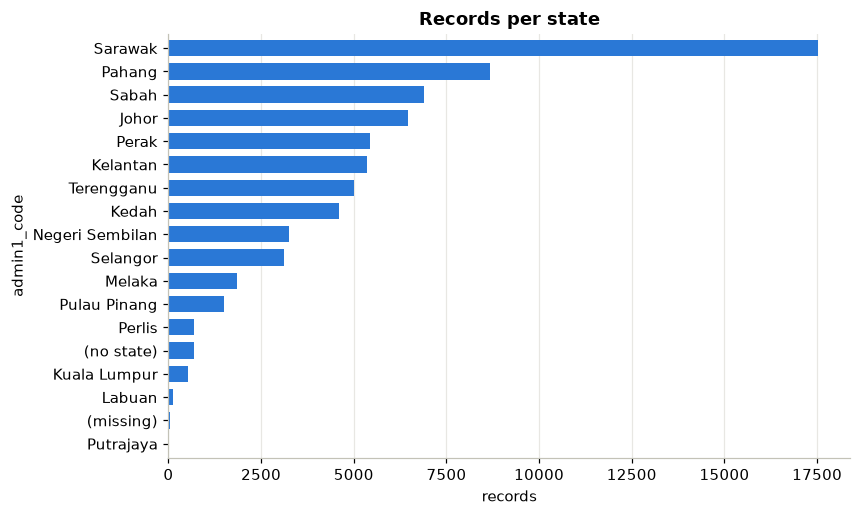

In [11]:
STATE = (df.loc[df["feature_code"] == "ADM1", ["admin1_code", "name"]]
           .set_index("admin1_code")["name"].to_dict())
STATE["00"] = "(no state)"

states = df["admin1_code"].map(STATE).fillna("(missing)").value_counts()
ax = states.sort_values().plot.barh(color=ACCENT, figsize=(8, 5), width=0.7)
ax.set_title("Records per state")
ax.set_xlabel("records")
ax.grid(axis="y", visible=False)
plt.show()

Sarawak has the most records: it is the largest state, with many rivers.
Code `00` is used for features not inside a single state, such as offshore features and the country itself.

## 7. Numeric columns

In [12]:
df[["latitude", "longitude", "population", "dem"]].describe().round(2)

,latitude,longitude,population,dem
count,71709.00,71709.00,71709.00,71709.00
mean,3.76,105.98,1545.57,-119.01
std,1.62,5.71,125380.92,1513.63
min,0.33,2.81,0.00,-9999.00
25%,2.34,101.78,0.00,12.00
50%,3.74,102.88,0.00,36.00
75%,5.21,111.50,0.00,96.00
max,7.95,124.12,31528585.00,4046.00


### Population

The column is very skewed: most values are 0 (unknown), and the rest span several orders of magnitude.
We plot only the known values, on a log scale.

feature_class
P    750
A     36
L      3
T      1
S      1
Name: count, dtype: int64


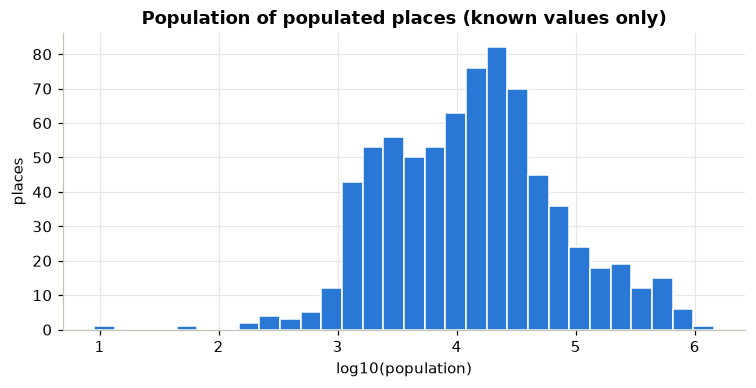

In [13]:
pop = df.loc[df["population"] > 0]
print(pop["feature_class"].value_counts())

ax = np.log10(pop.loc[pop["feature_class"] == "P", "population"]).plot.hist(
    bins=30, color=ACCENT, edgecolor="white", figsize=(8, 3.5))
ax.set_title("Population of populated places (known values only)")
ax.set_xlabel("log10(population)")
ax.set_ylabel("places")
plt.show()

- Population is known for **750 populated places** (`P`) and 36 admin areas (`A`).
- Admin-area populations are totals (Malaysia ~31.5M, Selangor ~7M). They **double count** the cities inside them,
  so we must not mix `A` rows with `P` rows.
- City populations range from a few hundred people up to Kuala Lumpur (~1.45M).

In [14]:
df.loc[df["feature_class"] == "P"].nlargest(10, "population")[
    ["name", "feature_code", "population", "admin1_code"]]

,name,feature_code,population,admin1_code
2767,Kuala Lumpur,PPLC,1453975,14
376,Johor Bahru,PPLA,858118,01
38398,Kampung Baru Subang,PPL,833571,12
2764,Petaling Jaya,PPLA2,807879,12
2243,Ipoh,PPLA,759952,07
527,Shah Alam,PPL,740750,12
66807,Subang Jaya,PPLX,708296,12
71434,Bukit Rahman Putra,PPL,607000,12
371,Pelentong,PPL,583640,01
2368,Malacca,PPLA,579000,04


### Elevation (`dem`)

We replace the `-9999` sentinel with `NaN` before looking at the distribution.

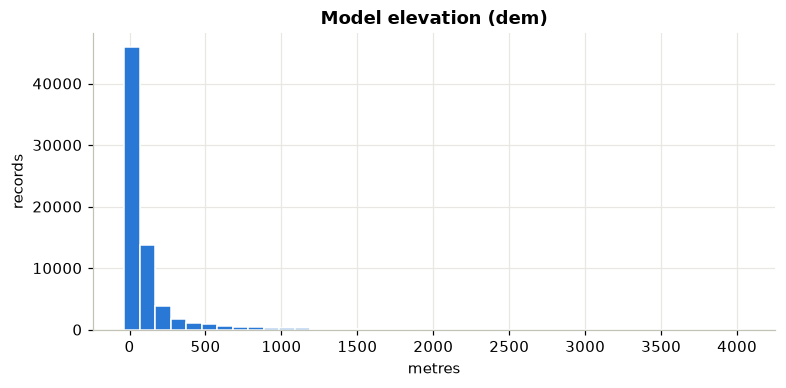

In [15]:
dem = df["dem"].replace(-9999, np.nan)
ax = dem.plot.hist(bins=40, color=ACCENT, edgecolor="white", figsize=(8, 3.5))
ax.set_title("Model elevation (dem)")
ax.set_xlabel("metres")
ax.set_ylabel("records")
plt.show()

Most features are low-lying (median ~36 m). The tail reaches Mount Kinabalu (~4,000 m).
Elevation could help a variant where road cost depends on terrain.

## 8. Geographic distribution

Malaysia's latitude runs roughly 0.8°N–7.5°N and its longitude roughly 99.5°E–119.5°E. We flag any points outside this box.

In [16]:
out_of_box = ~df["latitude"].between(0.8, 7.5) | ~df["longitude"].between(99.5, 119.5)
df.loc[out_of_box, ["geonameid", "name", "feature_code", "latitude", "longitude", "admin1_code"]]

,geonameid,name,feature_code,latitude,longitude,admin1_code
28,1222409,Perak Island,ISL,5.68365,98.93849,02
37019,1769636,Kampong Diri,PPL,0.33333,111.56667,11
42912,1775555,Sungai Engkalat,STM,2.81070,2.81070,11
50985,1892344,Membatuaan,RK,7.95000,117.25500,16
50999,1892364,North Borneo Dangers,SHOL,7.03833,124.12500,16
51000,1892365,Northwest Borneo Dangers,SHOL,7.03000,124.05000,16


- **`Sungai Engkalat`** has longitude = latitude = 2.8107. That puts it in the Atlantic Ocean, so this is a **data-entry error**.
- The two `SHOL` "Dangers" rows and `Membatuaan` are offshore shoals and rocks in the South China Sea and Sulu Sea.
- `Perak Island` (98.9°E) and `Kampong Diri` (0.33°N) are real places just outside the rough box.

None of these are populated places except `Kampong Diri`, and it has no population. Filtering to `P` with population > 0 removes all of them.

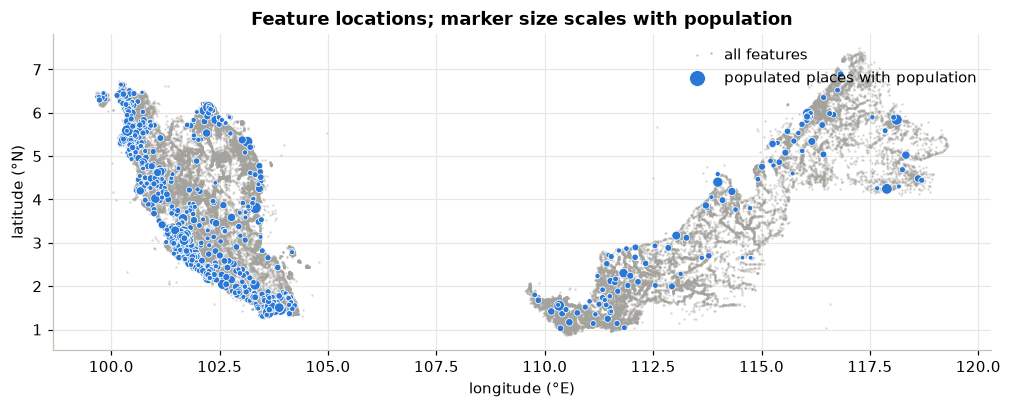

In [17]:
geo = df.loc[~out_of_box]
cities = geo.loc[(geo["feature_class"] == "P") & (geo["population"] > 0)]

fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(geo["longitude"], geo["latitude"], s=0.3, color=MUTED, alpha=0.4, label="all features")
ax.scatter(cities["longitude"], cities["latitude"], s=np.sqrt(cities["population"]) / 15 + 8,
           color=ACCENT, edgecolor="white", linewidth=0.5, label="populated places with population")
ax.set_title("Feature locations; marker size scales with population")
ax.set_xlabel("longitude (°E)")
ax.set_ylabel("latitude (°N)")
ax.set_aspect("equal")
ax.legend(loc="upper right", frameon=False, markerscale=1.5)
plt.show()

The data sits in **two separate land masses**:

- **Peninsular Malaysia** (longitude < 105°E)
- **East Malaysia** (Sabah, Sarawak, Labuan; longitude > 109°E)

No record lies between 105°E and 109°E, because that is the South China Sea.

**TSP implication:** a straight-line (haversine) distance between the two regions crosses ~600 km of sea.
A realistic variant must handle this, for example with:

- a flight or ferry edge with a different cost,
- clustering by region first, or
- restricting the tour to one region.

Peninsular cities are also much denser than those in Borneo.

In [18]:
geo["longitude"].lt(105).map({True: "Peninsular", False: "East Malaysia"}).value_counts()

longitude
Peninsular       47032
East Malaysia    24671
Name: count, dtype: int64

## 9. Cleaning

We build a **candidate city table** for the TSP. Each step below is a documented filter (required by the brief, section 5).

| Step | Action | Reason |
|---|---|---|
| 1 | Keep `feature_class == "P"` | TSP nodes are places people live and visit |
| 2 | Drop `PPLH`, `PPLQ` | Historical / abandoned places cannot be visited |
| 3 | Keep `population > 0` | 0 = unknown; we want a meaningful weight for each city |
| 4 | Drop rows outside the Malaysia bounding box | Removes coordinate errors |
| 5 | Drop duplicate `(latitude, longitude)` | Avoids zero-distance edges |
| 6 | Replace `dem == -9999` with `NaN` | Sentinel, not a real elevation |
| 7 | Keep only the columns we use | Smaller, clearer dataset |
| 8 | Add `state` and `region` | Derived attributes for clustering / multi-salesperson variants |

In [19]:
steps = {"raw": len(df)}

clean = df.loc[df["feature_class"] == "P"]
steps["1. populated places"] = len(clean)

clean = clean.loc[~clean["feature_code"].isin(["PPLH", "PPLQ"])]
steps["2. drop historical/abandoned"] = len(clean)

clean = clean.loc[clean["population"] > 0]
steps["3. population known"] = len(clean)

clean = clean.loc[clean["latitude"].between(0.8, 7.5) & clean["longitude"].between(99.5, 119.5)]
steps["4. inside Malaysia box"] = len(clean)

clean = clean.drop_duplicates(["latitude", "longitude"])
steps["5. unique coordinates"] = len(clean)

clean = clean.assign(
    dem=clean["dem"].replace(-9999, np.nan),
    state=clean["admin1_code"].map(STATE),
    region=np.where(clean["longitude"] < 105, "Peninsular", "East Malaysia"),
)[["geonameid", "name", "asciiname", "latitude", "longitude",
   "feature_code", "population", "dem", "admin1_code", "state", "region"]]
clean = clean.sort_values("population", ascending=False).reset_index(drop=True)

pd.Series(steps, name="rows remaining")

raw                             71709
1. populated places             21672
2. drop historical/abandoned    21578
3. population known               745
4. inside Malaysia box            745
5. unique coordinates             745
Name: rows remaining, dtype: int64

In [20]:
clean.isna().sum()

geonameid       0
name            0
asciiname       0
latitude        0
longitude       0
feature_code    0
population      0
dem             5
admin1_code     0
state           0
region          0
dtype: int64

In [21]:
clean.head(10)

,geonameid,name,asciiname,latitude,longitude,feature_code,population,dem,admin1_code,state,region
0,1735161,Kuala Lumpur,Kuala Lumpur,3.14120,101.68653,PPLC,1453975,56.0,14,Kuala Lumpur,Peninsular
1,1732752,Johor Bahru,Johor Bahru,1.46550,103.75780,PPLA,858118,32.0,01,Johor,Peninsular
2,1771023,Kampung Baru Subang,Kampung Baru Subang,3.15000,101.53333,PPL,833571,27.0,12,Selangor,Peninsular
3,1735158,Petaling Jaya,Petaling Jaya,3.10726,101.60671,PPLA2,807879,45.0,12,Selangor,Peninsular
4,1734634,Ipoh,Ipoh,4.58410,101.08290,PPLA,759952,45.0,07,Perak,Peninsular
5,1732903,Shah Alam,Shah Alam,3.08507,101.53281,PPL,740750,53.0,12,Selangor,Peninsular
6,8504423,Subang Jaya,Subang Jaya,3.04384,101.58062,PPLX,708296,41.0,12,Selangor,Peninsular
7,13118225,Bukit Rahman Putra,Bukit Rahman Putra,3.21727,101.56080,PPL,607000,76.0,12,Selangor,Peninsular
8,1732747,Pelentong,Pelentong,1.52430,103.82400,PPL,583640,25.0,01,Johor,Peninsular
9,1734759,Malacca,Malacca,2.19600,102.24050,PPLA,579000,6.0,04,Melaka,Peninsular


In [22]:
clean.groupby("region")["population"].agg(["count", "sum", "median"])

,count,sum,median
region,,,
East Malaysia,103,4418777,15333.0
Peninsular,642,35099387,13365.0


The city populations sum to ~39.5M, which is more than Malaysia's ~31.5M.
Some places overlap: for example, `PPLX` suburbs such as Subang Jaya sit inside larger urban areas.
Treat population as a **relative weight** for each city, not as counts you can add up.

In [23]:
clean.to_csv(DATA_DIR / "cities_clean.csv", index=False)
print(f"saved {len(clean)} cities to {DATA_DIR / 'cities_clean.csv'}")

saved 745 cities to data\cities_clean.csv


### 9.1 Columns kept after cleaning

Profile of each column in `cities_clean.csv`.

In [24]:
def profile(s):
    num = pd.api.types.is_numeric_dtype(s)
    return pd.Series({
        "dtype": str(s.dtype),
        "non_null": s.notna().sum(),
        "missing": s.isna().sum(),
        "unique": s.nunique(),
        "min": s.min() if num else "",
        "max": s.max() if num else "",
        "example": s.iloc[0],
    })

clean.apply(profile).T

,dtype,non_null,missing,unique,min,max,example
geonameid,int64,745,0,745,1222387,13118391,1735161
name,str,745,0,742,,,Kuala Lumpur
asciiname,str,745,0,742,,,Kuala Lumpur
latitude,float64,745,0,717,1.02656,6.88732,3.1412
longitude,float64,745,0,716,99.68252,118.69287,101.68653
feature_code,str,745,0,8,,,PPLC
population,int64,745,0,667,9,1453975,1453975
dem,float64,740,5,141,-18.0,1546.0,56.0
admin1_code,string,745,0,16,,,14
state,str,745,0,16,,,Kuala Lumpur


### 9.2 Final data dictionary

| Column | Source | Meaning | Units / values | Use in TSP |
|---|---|---|---|---|
| `geonameid` | original | Unique GeoNames ID of the place | integer | Node ID; join key back to `MY.txt` |
| `name` | original | Place name in UTF-8 | text, may contain `’` | Label in output and plots |
| `asciiname` | original | `name` in plain ASCII | text | Safe label for console / CSV tools |
| `latitude` | original | North–south position | decimal degrees, WGS84 (1.03 to 6.89) | Distance calculation (e.g. haversine) |
| `longitude` | original | East–west position | decimal degrees, WGS84 (99.68 to 118.69) | Distance calculation; region split |
| `feature_code` | original | Type of populated place | `PPL`, `PPLA`, `PPLA2`, `PPLC`, `PPLG`, `PPLX`, `PPLL`, `PPLS` | City importance / priority |
| `population` | original | Number of inhabitants (always > 0 after cleaning) | people (9 to 1,453,975) | City weight / priority; size threshold |
| `dem` | original, cleaned | Model elevation; `-9999` replaced with `NaN` | metres (-18 to 1,546; 5 missing) | Optional terrain cost |
| `admin1_code` | original | FIPS state code | `01`–`17` (16 states and territories; no `10`) | Grouping key for states |
| `state` | **derived** | State name, mapped from `admin1_code` using the `ADM1` rows | text, e.g. `Selangor` | Clustering; multi-salesperson split |
| `region` | **derived** | `Peninsular` if longitude < 105°E, else `East Malaysia` | 2 values | Handle the sea crossing; per-region tours |

### 9.3 Columns dropped

| Column | Reason |
|---|---|
| `alternatenames` | Not needed; 38% empty |
| `feature_class` | Constant (`P`) after filtering |
| `country_code` | Constant (`MY`) |
| `cc2` | >99% empty |
| `admin2_code` | District level not needed; `state` is enough |
| `admin3_code`, `admin4_code` | >99% empty |
| `elevation` | ~97% empty; `dem` covers it |
| `timezone` | All Malaysian zones are UTC+8 |
| `modification_date` | Metadata only |

## 10. Choosing the TSP problem size

The brief requires us to justify the dataset size. A complete graph on *n* cities has *n(n−1)/2* edges.
For the baseline nearest-neighbour heuristic this means O(n²) time, and a full distance matrix needs O(n²) memory.

In [25]:
sizes = pd.DataFrame({"min_population": [0, 1_000, 5_000, 15_000, 50_000, 100_000]})
sizes["cities"] = [(clean["population"] > t).sum() for t in sizes["min_population"]]
sizes["edges (complete graph)"] = sizes["cities"] * (sizes["cities"] - 1) // 2
sizes["Peninsular"] = [((clean["population"] > t) & (clean["region"] == "Peninsular")).sum()
                       for t in sizes["min_population"]]
sizes["East Malaysia"] = sizes["cities"] - sizes["Peninsular"]
sizes

,min_population,cities,edges (complete graph),Peninsular,East Malaysia
0,0,745,277140,642,103
1,1000,726,263175,626,100
2,5000,530,140185,450,80
3,15000,355,62835,302,53
4,50000,144,10296,127,17
5,100000,83,3403,75,8


Population thresholds give natural problem sizes from a few dozen to several hundred cities:

- small enough for a Python implementation,
- large enough that heuristics behave differently,
- easy to explain ("all towns over 15,000 people").

Exact solvers (e.g. Held–Karp, O(n²·2ⁿ)) are only feasible below ~20 cities.
Use the top-N cities for an optimality check against the heuristics.

## 11. Summary of findings

1. **71,709 records, 19 columns.** Coordinates, name and feature class are complete.
2. Only **~30%** of records are populated places. The rest are rivers, hills, buildings and other features.
3. **Population is unknown (0) for ~99% of rows.** About 750 populated places have a real population.
4. Admin-area rows (`A`) hold aggregate populations and must not be mixed with cities.
   Even city populations overlap (suburbs inside cities), so use them as weights, not sums.
5. Columns that are mostly empty (`admin3/4_code`, `cc2`, `elevation`) or constant (`country_code`) are dropped.
6. `dem` uses `-9999` as "no data"; it is replaced with `NaN`.
7. One coordinate error was found (`Sungai Engkalat`, longitude = latitude). Some offshore points fall outside the land area.
8. Names repeat often, so `geonameid` is the key.
9. Malaysia is **two land masses separated by sea**. This is a natural reason to break the classic TSP assumption that straight-line distance is the travel cost.
10. The cleaned table `data/cities_clean.csv` has **745 populated places** with known population (642 Peninsular, 103 East Malaysia).
    It adds derived `state` and `region` columns.